# Explainable AI

## TRUST-XIDS — Notebook 6

Explains model predictions using **SHAP** and **LIME**, and investigates
whether those explanations give meaningful insight into intrusion
detection.

**Scope:** this notebook deliberately explains models trained on the
**full UNSW-NB15 feature set only** (`rf_unsw_full`, `xgb_unsw_full`,
`svm_unsw_full`, `cnn_unsw_full`, all saved in Notebook 4/5) — not the
8-feature harmonized cross-dataset models. The harmonized set drops
`sttl` and `ct_srv_dst`, UNSW-NB15's two most important features by both
Notebook 3's Random Forest importances and the base literature on this
dataset, so explaining the harmonized models would mean explaining a
deliberately impoverished feature set rather than the models that actually
matter for understanding *this dataset's* intrusion-detection behaviour.
CICIDS2017 explainability and cross-dataset explanation comparison are out
of scope for this notebook by the same reasoning stated in the project
brief's non-negotiable restrictions.

# 1. Import Libraries and Load Models

In [5]:
import os
import json

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

import shap
import lime
import lime.lime_tabular

import joblib
from tensorflow import keras

BASE_DIR = r"C:\Users\Anu\OneDrive\Desktop\IDS"
PROCESSED_DIR = os.path.join(BASE_DIR, "data/processed")
MODELS_DIR = os.path.join(BASE_DIR, "models")

RANDOM_STATE = 42

print("shap version:", shap.__version__)
print("lime imported successfully")

shap version: 0.44.1
lime imported successfully


In [6]:
with open(os.path.join(PROCESSED_DIR, "feature_metadata.json")) as f:
    feature_metadata = json.load(f)

unsw_feature_cols = feature_metadata["unsw_final_feature_cols"]

unsw_train = pd.read_csv(os.path.join(PROCESSED_DIR, "unsw_train_selected.csv"))
unsw_test = pd.read_csv(os.path.join(PROCESSED_DIR, "unsw_test_selected.csv"))

X_unsw_train = unsw_train[unsw_feature_cols]
y_unsw_train = unsw_train["label"]
X_unsw_test = unsw_test[unsw_feature_cols]
y_unsw_test = unsw_test["label"]

print("UNSW train:", X_unsw_train.shape, " test:", X_unsw_test.shape)

UNSW train: (175341, 33)  test: (82332, 33)


In [8]:
rf_unsw = joblib.load(os.path.join(MODELS_DIR, "rf_unsw_full.joblib"))
xgb_unsw = joblib.load(os.path.join(MODELS_DIR, "xgb_unsw_full.joblib"))
svm_unsw = joblib.load(os.path.join(MODELS_DIR, "svm_unsw_full.joblib"))

unsw_svm_scaler = joblib.load(os.path.join(MODELS_DIR, "unsw_svm_scaler.joblib"))

cnn_path = os.path.join(MODELS_DIR, "cnn_unsw_full.keras")
cnn_unsw = keras.models.load_model(cnn_path) if os.path.exists(cnn_path) else None
unsw_cnn_scaler_path = os.path.join(MODELS_DIR, "unsw_cnn_scaler.joblib")
unsw_cnn_scaler = joblib.load(unsw_cnn_scaler_path) if os.path.exists(unsw_cnn_scaler_path) else None

print("Models loaded:", "RF" , "XGBoost", "SVM", "1D-CNN" if cnn_unsw is not None else "1D-CNN (not found - run Notebook 5 first)")

Models loaded: RF XGBoost SVM 1D-CNN


# 2. SHAP Explanations

**What is being explained:** for Random Forest and XGBoost, SHAP values are
computed on the **probability of the Attack class (label=1)** using
`TreeExplainer`, which is exact and fast for tree ensembles. For SVM, SHAP
values are computed on the scaled feature space (since the model itself
operates on scaled inputs) using `KernelExplainer`, which is model-agnostic
but far more expensive — so it is run on a small background + explanation
sample, documented explicitly below, not the full test set.

SHAP values from the tree models (probability-of-attack scale) and the SVM
KernelExplainer (also probability-of-attack scale here, since
`predict_proba` is the function being explained) are on a comparable scale
to each other, but are **not** directly compared to raw model margins or
log-odds — everything here is explained in probability space.

In [9]:
# Use a stratified sample of the training data as SHAP's background distribution,
# and a smaller sample of the test set for the explanations themselves - using the
# full ~175k-row test set for the slower explainers below would be impractical.

shap_background = X_unsw_train.sample(n=min(500, len(X_unsw_train)), random_state=RANDOM_STATE)
shap_sample = X_unsw_test.sample(n=min(500, len(X_unsw_test)), random_state=RANDOM_STATE)

print("SHAP background sample:", shap_background.shape)
print("SHAP explanation sample:", shap_sample.shape)

SHAP background sample: (500, 33)
SHAP explanation sample: (500, 33)


In [10]:
explainer_rf = shap.TreeExplainer(rf_unsw)
shap_values_rf = explainer_rf.shap_values(shap_sample)

# For a binary sklearn RandomForestClassifier, shap_values is either a list
# [class_0_values, class_1_values] or a single (n, features, 2) array
# depending on the shap version - normalize to "attack class" values here.
if isinstance(shap_values_rf, list):
    shap_values_rf_attack = shap_values_rf[1]
elif shap_values_rf.ndim == 3:
    shap_values_rf_attack = shap_values_rf[:, :, 1]
else:
    shap_values_rf_attack = shap_values_rf

print("SHAP values (Random Forest, attack-class probability) computed. Shape:", shap_values_rf_attack.shape)

SHAP values (Random Forest, attack-class probability) computed. Shape: (500, 33)


The figure layout has changed to tight


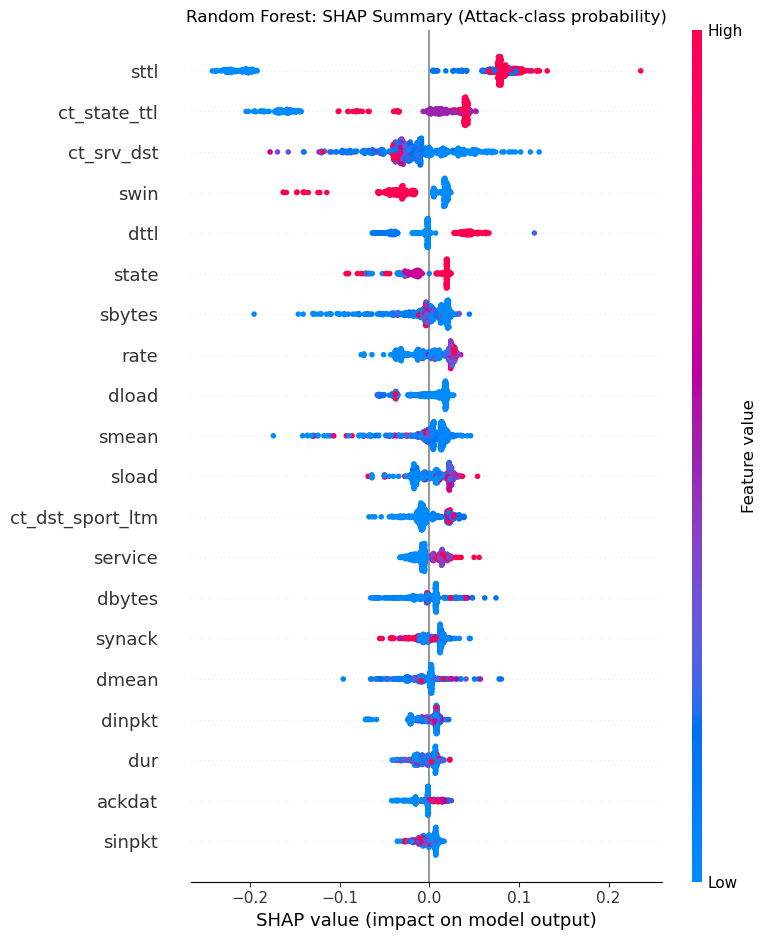

In [11]:
shap.summary_plot(shap_values_rf_attack, shap_sample, show=False)
plt.title("Random Forest: SHAP Summary (Attack-class probability)")
plt.tight_layout()
plt.show()

SHAP values computed. Shape: (500, 33)


The figure layout has changed to tight


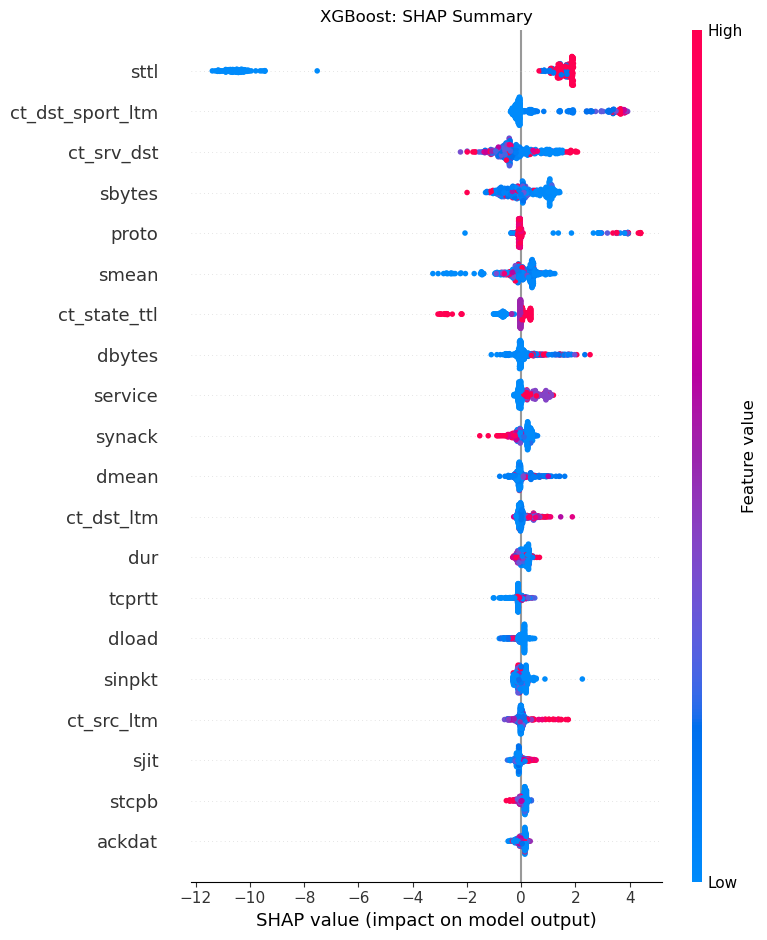

In [13]:
import xgboost as xgb
import shap
import matplotlib.pyplot as plt

booster = xgb_unsw.get_booster()

dmat = xgb.DMatrix(
    shap_sample,
    feature_names=list(shap_sample.columns)
    if hasattr(shap_sample, "columns")
    else None
)

# Calculate SHAP contribution values
shap_values_xgb = booster.predict(
    dmat,
    pred_contribs=True
)

# Remove the final column, which contains the bias contribution
shap_values_xgb = shap_values_xgb[:, :-1]

print("SHAP values computed. Shape:", shap_values_xgb.shape)

shap.summary_plot(
    shap_values_xgb,
    shap_sample,
    show=False
)

plt.title("XGBoost: SHAP Summary")
plt.tight_layout()
plt.show()

**SVM SHAP note:** `KernelExplainer` treats the model as a black box
and needs to evaluate `predict_proba` many times per explained row — with
even a few hundred background/explanation rows this is orders of magnitude
slower than the tree explainers above. The sample sizes below are
deliberately small and documented, not a silent shortcut.

In [14]:
svm_shap_background = X_unsw_train.sample(n=min(100, len(X_unsw_train)), random_state=RANDOM_STATE)
svm_shap_sample = X_unsw_test.sample(n=min(50, len(X_unsw_test)), random_state=RANDOM_STATE)

svm_background_scaled = unsw_svm_scaler.transform(svm_shap_background)
svm_sample_scaled = unsw_svm_scaler.transform(svm_shap_sample)

def svm_predict_proba_attack(X):
    return svm_unsw.predict_proba(X)[:, 1]

explainer_svm = shap.KernelExplainer(svm_predict_proba_attack, svm_background_scaled)
shap_values_svm = explainer_svm.shap_values(svm_sample_scaled, nsamples=100)

print("SHAP values (SVM, attack-class probability, scaled-feature space) computed. Shape:", np.array(shap_values_svm).shape)

  0%|          | 0/50 [00:00<?, ?it/s]

SHAP values (SVM, attack-class probability, scaled-feature space) computed. Shape: (50, 33)


The figure layout has changed to tight


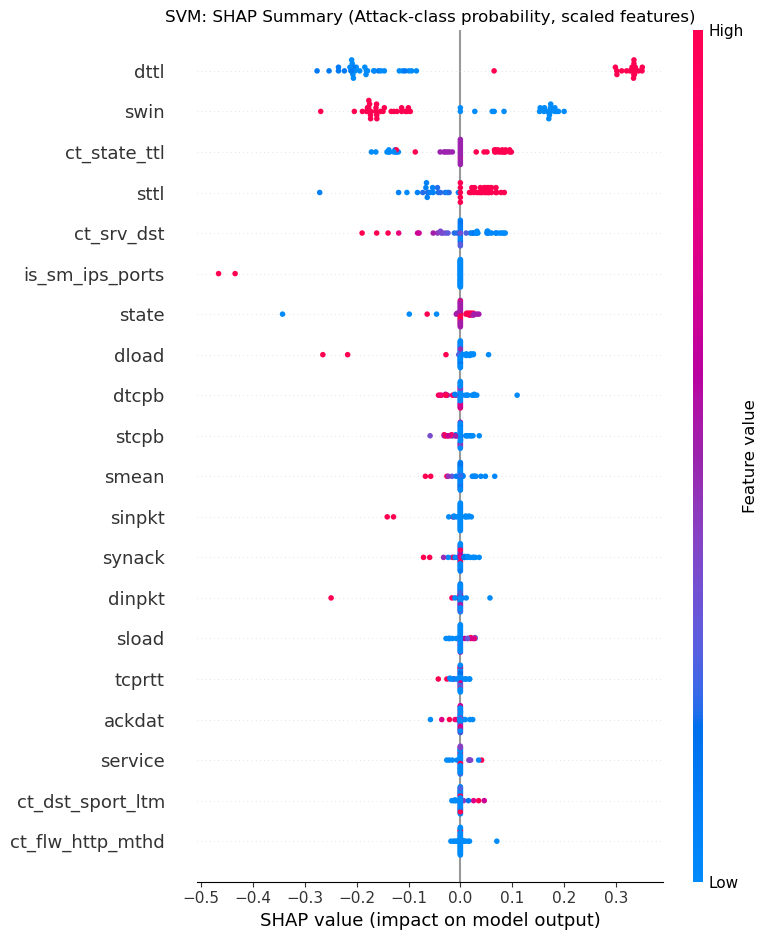

In [15]:
shap.summary_plot(shap_values_svm, svm_sample_scaled, feature_names=unsw_feature_cols, show=False)
plt.title("SVM: SHAP Summary (Attack-class probability, scaled features)")
plt.tight_layout()
plt.show()

# 3. Global Feature Importance Comparison (SHAP vs Random Forest `feature_importances_`)

Checking whether SHAP's ranking roughly agrees with the built-in Random
Forest importances from Notebook 3/4 — agreement is a sanity check, not a
requirement; the two measure related but not identical things (SHAP
reflects marginal contribution to this specific sample's predictions,
`feature_importances_` reflects average impurity reduction across all
training splits).

In [16]:
shap_importance_rf = pd.DataFrame({
    "feature": unsw_feature_cols,
    "mean_abs_shap": np.abs(shap_values_rf_attack).mean(axis=0)
}).sort_values("mean_abs_shap", ascending=False)

rf_builtin_importance = pd.read_csv(os.path.join(PROCESSED_DIR, "unsw_feature_importance.csv"))

comparison = shap_importance_rf.merge(rf_builtin_importance, on="feature", suffixes=("_shap", "_builtin"))
comparison = comparison.sort_values("mean_abs_shap", ascending=False)

print("Top 10 by SHAP vs top 10 by built-in importance (Random Forest):")
comparison.head(10)

Top 10 by SHAP vs top 10 by built-in importance (Random Forest):


,feature,mean_abs_shap,importance
0,sttl,0.108181,0.127009
1,ct_state_ttl,0.057883,0.123110
2,ct_srv_dst,0.034949,0.028173
3,swin,0.027875,0.003593
4,dttl,0.026488,0.045158
5,state,0.021106,0.013735
6,sbytes,0.020426,0.028015
7,rate,0.020012,0.062905
8,dload,0.018857,0.067356
9,smean,0.018340,0.029364


# 4. Local Explanations (LIME)

Four representative cases: a correctly classified benign flow, a correctly classified attack flow, a false positive, and a false negative (if one exists in the test set) — using the Random Forest model.

In [17]:
y_pred_rf = rf_unsw.predict(X_unsw_test)

correct_benign_idx = X_unsw_test[(y_unsw_test == 0) & (y_pred_rf == 0)].index
correct_attack_idx = X_unsw_test[(y_unsw_test == 1) & (y_pred_rf == 1)].index
false_positive_idx = X_unsw_test[(y_unsw_test == 0) & (y_pred_rf == 1)].index
false_negative_idx = X_unsw_test[(y_unsw_test == 1) & (y_pred_rf == 0)].index

print("Correctly classified benign :", len(correct_benign_idx))
print("Correctly classified attack :", len(correct_attack_idx))
print("False positives              :", len(false_positive_idx))
print("False negatives              :", len(false_negative_idx))

Correctly classified benign : 27253
Correctly classified attack : 44031
False positives              : 9747
False negatives              : 1301


In [18]:
lime_explainer = lime.lime_tabular.LimeTabularExplainer(
    X_unsw_train.values,
    feature_names=unsw_feature_cols,
    class_names=["Normal", "Attack"],
    mode="classification",
    random_state=RANDOM_STATE
)

def explain_row_with_lime(row_index, label_text):
    row = X_unsw_test.loc[row_index].values
    exp = lime_explainer.explain_instance(row, rf_unsw.predict_proba, num_features=10)
    print(f"LIME explanation - {label_text} (test row {row_index}):")
    for feature, weight in exp.as_list():
        print(f"  {feature:40s} {weight:+.4f}")
    print()
    return exp

print("LIME explainer ready.")

LIME explainer ready.


In [19]:
if len(correct_benign_idx) > 0:
    explain_row_with_lime(correct_benign_idx[0], "Correctly classified BENIGN")

LIME explanation - Correctly classified BENIGN (test row 8):
  sttl <= 62.00                            -0.2384
  1.00 < ct_state_ttl <= 2.00              +0.0983
  swin <= 0.00                             +0.0611
  is_sm_ips_ports > 0.00                   -0.0501
  dttl <= 0.00                             -0.0347
  ct_srv_dst <= 2.00                       +0.0345
  2.00 < state <= 3.00                     +0.0291
  service <= 0.00                          -0.0198
  dur <= 0.00                              +0.0135
  1.00 < ct_dst_sport_ltm <= 3.00          +0.0127



X does not have valid feature names, but RandomForestClassifier was fitted with feature names


In [20]:
if len(correct_attack_idx) > 0:
    explain_row_with_lime(correct_attack_idx[0], "Correctly classified ATTACK")

LIME explanation - Correctly classified ATTACK (test row 243):
  62.00 < sttl <= 254.00                   +0.2360
  1.00 < ct_state_ttl <= 2.00              +0.0950
  swin <= 0.00                             +0.0642
  ct_srv_dst <= 2.00                       +0.0348
  dttl <= 0.00                             -0.0320
  2.00 < state <= 3.00                     +0.0271
  is_sm_ips_ports <= 0.00                  +0.0268
  service <= 0.00                          -0.0213
  ct_dst_sport_ltm <= 1.00                 -0.0184
  dmean <= 0.00                            -0.0149



X does not have valid feature names, but RandomForestClassifier was fitted with feature names


In [21]:
if len(false_positive_idx) > 0:
    explain_row_with_lime(false_positive_idx[0], "FALSE POSITIVE (benign flagged as attack)")
else:
    print("No false positives in this run to explain.")

LIME explanation - FALSE POSITIVE (benign flagged as attack) (test row 0):
  62.00 < sttl <= 254.00                   +0.2313
  1.00 < ct_state_ttl <= 2.00              +0.0935
  swin <= 0.00                             +0.0627
  is_sm_ips_ports <= 0.00                  +0.0391
  ct_srv_dst <= 2.00                       +0.0334
  dttl <= 0.00                             -0.0327
  2.00 < state <= 3.00                     +0.0271
  service <= 0.00                          -0.0197
  ct_dst_sport_ltm <= 1.00                 -0.0187
  sjit <= 0.00                             +0.0104



X does not have valid feature names, but RandomForestClassifier was fitted with feature names


In [22]:
if len(false_negative_idx) > 0:
    explain_row_with_lime(false_negative_idx[0], "FALSE NEGATIVE (attack missed)")
else:
    print("No false negatives in this run to explain.")

LIME explanation - FALSE NEGATIVE (attack missed) (test row 295):
  sttl <= 62.00                            -0.2362
  ct_state_ttl <= 1.00                     -0.0988
  29.00 < dttl <= 252.00                   +0.0689
  0.00 < swin <= 255.00                    -0.0580
  is_sm_ips_ports <= 0.00                  +0.0290
  state <= 2.00                            -0.0278
  synack > 0.02                            -0.0180
  ct_dst_sport_ltm <= 1.00                 -0.0169
  dmean > 89.00                            +0.0143
  service > 2.00                           +0.0139



X does not have valid feature names, but RandomForestClassifier was fitted with feature names


# 5. Interpretation

Distinguishing what the numbers above can and cannot support:

- **Statistically important vs. plausible cybersecurity meaning.** `sttl`
  (time-to-live) and `ct_state_ttl` ranking highly is both statistically
  supported (top SHAP + built-in importance) and has a plausible security
  interpretation — TTL patterns differ between normal routing and certain
  attack traffic (e.g. spoofed packets, scans) that doesn't follow the same
  network path. This is a case where statistical and domain-plausible
  importance agree.
- **Possible dataset artifacts.** `rate` and the `ct_*` connection-count
  features are partly derived from how UNSW-NB15's testbed generated
  traffic in short time windows — high importance here could reflect
  genuine attack behaviour or a property of how this specific dataset was
  captured. This project cannot distinguish the two without an independent
  dataset using the same feature definitions, which (per Notebook 3) is
  exactly the gap the harmonized 8-feature cross-dataset set cannot close
  for `sttl`/`ct_srv_dst` specifically.
- **Features an attacker could realistically change.** Packet/byte counts
  and timing-derived features (`rate`, `sload`, `dload`) are more directly
  under an attacker's control (e.g. by pacing or padding traffic) than
  `sttl`, which depends on network topology rather than payload content.
  A model relying heavily on attacker-controllable features is more
  evadable than one relying on structural signals.
- **Importance is not causality.** A high SHAP value for a feature in this
  dataset does not establish that changing that feature *causes* a change
  in attack likelihood in the real world — only that the model's learned
  decision boundary is sensitive to it, in this data.

# 6. Explanation Evaluation (Ablation Test)

A simple, honest quantitative check: if the top-N SHAP features for Random
Forest are genuinely driving predictions, removing them (replacing with
the training-set mean) and re-evaluating on the same test rows should
measurably hurt performance; removing the bottom-N (least important)
features should barely matter. This is a feature-ablation test, one of the
methods suggested in the project brief for evaluating explanation quality.

In [23]:
def ablation_test(model, X_test, y_test, feature_cols, cols_to_ablate, train_means):
    X_ablated = X_test.copy()
    for col in cols_to_ablate:
        X_ablated[col] = train_means[col]

    y_proba = model.predict_proba(X_ablated)[:, 1]
    y_pred = model.predict(X_ablated)

    from sklearn.metrics import f1_score, roc_auc_score
    return {
        "f1": f1_score(y_test, y_pred, zero_division=0),
        "roc_auc": roc_auc_score(y_test, y_proba)
    }

train_means = X_unsw_train.mean()

top_n = 5
top_features = shap_importance_rf["feature"].head(top_n).tolist()
bottom_features = shap_importance_rf["feature"].tail(top_n).tolist()

baseline_pred = rf_unsw.predict(X_unsw_test)
baseline_proba = rf_unsw.predict_proba(X_unsw_test)[:, 1]
from sklearn.metrics import f1_score, roc_auc_score
baseline_metrics = {
    "f1": f1_score(y_unsw_test, baseline_pred, zero_division=0),
    "roc_auc": roc_auc_score(y_unsw_test, baseline_proba)
}

top_ablated_metrics = ablation_test(rf_unsw, X_unsw_test, y_unsw_test, unsw_feature_cols, top_features, train_means)
bottom_ablated_metrics = ablation_test(rf_unsw, X_unsw_test, y_unsw_test, unsw_feature_cols, bottom_features, train_means)

ablation_results = pd.DataFrame([
    {"scenario": "Baseline (no ablation)", **baseline_metrics},
    {"scenario": f"Top {top_n} SHAP features ablated ({top_features})", **top_ablated_metrics},
    {"scenario": f"Bottom {top_n} SHAP features ablated ({bottom_features})", **bottom_ablated_metrics},
])

ablation_results

,scenario,f1,roc_auc
0,Baseline (no ablation),0.888528,0.975194
1,"Top 5 SHAP features ablated (['sttl', 'ct_stat...",0.762000,0.825352
2,Bottom 5 SHAP features ablated (['is_sm_ips_po...,0.882765,0.974749


**Interpretation:** if ablating the top-SHAP features causes a much
larger F1/ROC-AUC drop than ablating the bottom-SHAP features, that is
corroborating (not conclusive) evidence that SHAP's ranking reflects
features the model actually depends on for this test set — not merely an
artifact of how SHAP values are computed. If the gap is small, that is
also a valid and reportable finding: it would suggest Random Forest here
has redundant, overlapping signal across many features rather than relying
narrowly on a handful.

# 7. Save Explainability Artifacts

In [24]:
import joblib

explain_dir = os.path.join(BASE_DIR, "artifacts", "explainability")
os.makedirs(explain_dir, exist_ok=True)

shap_importance_rf.to_csv(os.path.join(explain_dir, "shap_importance_rf_unsw.csv"), index=False)
ablation_results.to_csv(os.path.join(explain_dir, "ablation_results_rf_unsw.csv"), index=False)
comparison.to_csv(os.path.join(explain_dir, "shap_vs_builtin_importance_rf_unsw.csv"), index=False)

print("Explainability artifacts saved to", explain_dir)

Explainability artifacts saved to C:\Users\Anu\OneDrive\Desktop\IDS\artifacts\explainability


# 8. Summary

**Fill in after running on the full dataset:**

- Report the actual top-10 SHAP features for Random Forest, XGBoost, and
  SVM (printed above) and whether they agree with each other and with the
  Notebook 3/4 built-in Random Forest importance ranking.
- Report the actual LIME explanations captured for the correctly-classified
  benign/attack cases and any false positive/false negative found - note
  whether the features LIME highlights for a given row match that row's
  top global SHAP features, or diverge (both are valid findings).
- Report the actual ablation-test numbers (Section 6) - state explicitly
  whether ablating the top-5 SHAP features caused a materially larger
  performance drop than ablating the bottom-5, and what that does or does
  not establish about SHAP's ranking being meaningful versus an artifact.
- Note any case where SHAP and the built-in Random Forest importance
  substantially disagree, and discuss a plausible reason (e.g. a feature
  with many low-impact splits across many trees versus one with a few
  high-impact splits).
